# Modelado Predictivo: Clasificación con K-Nearest Neighbors (KNN)

**Proyecto:** Clasificador de Salud Fetal (Cardiotocography - UCI)

**Objetivo:** Implementar KNN desde cero con NumPy, comparar distintos valores de **k** y evaluar el modelo con una partición estratificada, sin utilizar los datos de prueba para seleccionar hiperparámetros.

**Archivo requerido:** `CTG_clean.csv`, ubicado junto a este notebook.

# Objetivos del Modelado

1. **Preparación de datos:** Revisar registros, clases, valores faltantes y duplicados.
2. **Partición estratificada:** Separar entrenamiento, validación y prueba conservando aproximadamente las proporciones de `NSP`.
3. **Estandarización:** Calcular la media y desviación estándar exclusivamente con los datos de entrenamiento.
4. **Comparación de hiperparámetros:** Evaluar distintos valores de **k** sobre validación mediante **F1 macro**, sin consultar prueba.
5. **Evaluación final:** Reentrenar con entrenamiento y validación y evaluar una sola vez sobre prueba, incluyendo matriz de confusión, precisión, recall y F1 por clase.

#### **Importación de librerías y definición del clasificador KNN**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

np.random.seed(42)

In [2]:
class KNNClassifier:
    """Clasificador KNN implementado desde cero con NumPy."""

    def __init__(self, k=5):
        if not isinstance(k, (int, np.integer)) or k < 1:
            raise ValueError("k debe ser un entero mayor o igual que 1.")
        self.k = k

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if X.ndim != 2:
            raise ValueError("X debe ser una matriz bidimensional.")
        if y.ndim != 1 or len(X) != len(y):
            raise ValueError("y debe ser un vector con una etiqueta por observación.")
        if len(X) == 0:
            raise ValueError("El conjunto de entrenamiento no puede estar vacío.")
        if not np.isfinite(X).all():
            raise ValueError("X contiene valores NaN o infinitos.")
        if self.k > len(X):
            raise ValueError("k no puede ser mayor que el número de observaciones de entrenamiento.")

        self.X_train = X
        self.y_train = y
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim != 2 or X.shape[1] != self.X_train.shape[1]:
            raise ValueError("X debe tener el mismo número de características que X_train.")
        if not np.isfinite(X).all():
            raise ValueError("X contiene valores NaN o infinitos.")

        predictions = []

        for x in X:
            # Distancia euclidiana desde la observación actual a todo el entrenamiento
            distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))
            nearest_indices = np.argsort(distances)[:self.k]
            nearest_labels = self.y_train[nearest_indices]

            # Votación por mayoría usando las clases originales, sin asumir etiquetas 0, 1, 2...
            votes = np.array([np.sum(nearest_labels == label) for label in self.classes_])
            predictions.append(self.classes_[np.argmax(votes)])

        return np.asarray(predictions)


def confusion_matrix(y_true, y_pred, labels):
    """Matriz de confusión con orden de clases explícito."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = np.asarray(labels)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true y y_pred deben tener la misma forma.")

    label_to_index = {label: i for i, label in enumerate(labels)}
    matrix = np.zeros((len(labels), len(labels)), dtype=int)

    for real, predicted in zip(y_true, y_pred):
        if real not in label_to_index or predicted not in label_to_index:
            raise ValueError("Se encontró una etiqueta que no está incluida en labels.")
        matrix[label_to_index[real], label_to_index[predicted]] += 1

    return matrix


def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))


def recall_per_class(matrix):
    recalls = []
    for i in range(len(matrix)):
        tp = matrix[i, i]
        fn = np.sum(matrix[i, :]) - tp
        recalls.append(tp / (tp + fn) if (tp + fn) > 0 else 0.0)
    return np.asarray(recalls)


def precision_per_class(matrix):
    precisions = []
    for i in range(len(matrix)):
        tp = matrix[i, i]
        fp = np.sum(matrix[:, i]) - tp
        precisions.append(tp / (tp + fp) if (tp + fp) > 0 else 0.0)
    return np.asarray(precisions)


def f1_per_class(precisions, recalls):
    denominator = precisions + recalls
    return np.divide(
        2 * precisions * recalls,
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator != 0
    )

#### **Carga, auditoría y limpieza de datos**

In [3]:
df_original = pd.read_csv("CTG_clean.csv")
assert "NSP" in df_original.columns, "No se encontró la variable objetivo NSP."
assert df_original.select_dtypes(include="number").shape[1] == df_original.shape[1], "Existen columnas no numéricas."
assert not df_original.isna().any().any(), "Existen valores faltantes; deben tratarse antes del modelado."

n_duplicados = int(df_original.duplicated().sum())
df_clean = df_original.drop_duplicates().reset_index(drop=True)

print(f"Registros originales: {len(df_original)}")
print(f"Duplicados exactos retirados antes de la partición: {n_duplicados}")
print(f"Registros utilizados: {len(df_clean)}")
print(f"Variables predictoras: {df_clean.shape[1] - 1}")
print("\nDistribución de clases:")
display(df_clean["NSP"].value_counts().sort_index().rename("Registros").to_frame())
display(df_clean.head())

Registros originales: 2126
Duplicados exactos retirados antes de la partición: 12
Registros utilizados: 2114
Variables predictoras: 21

Distribución de clases:


,Registros
NSP,
1.0,1647
2.0,292
3.0,175


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,10.4,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,13.4,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,23.0,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


#### **Partición estratificada y estandarización Z-score**

Se reserva el **20 % para prueba** y, del 80 % restante, el **25 % para validación**. Esto produce aproximadamente 60 % entrenamiento, 20 % validación y 20 % prueba. La estratificación conserva las proporciones de las clases. El conjunto de prueba queda apartado hasta la evaluación final.

In [4]:
X = df_clean.drop(columns="NSP").to_numpy(dtype=float)
y = df_clean["NSP"].to_numpy()
class_labels = np.unique(y)
class_names = {1: "Normal", 2: "Sospechoso", 3: "Patológico"}

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)

mean_train = X_train.mean(axis=0)
std_train = X_train.std(axis=0)
std_train[std_train == 0] = 1.0
X_train_scaled = (X_train - mean_train) / std_train
X_val_scaled = (X_val - mean_train) / std_train

print(f"Entrenamiento: {len(y_train)} | Validación: {len(y_val)} | Prueba: {len(y_test)}")
distribution = pd.DataFrame({
    "Entrenamiento": pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "Validación": pd.Series(y_val).value_counts(normalize=True).sort_index(),
    "Prueba": pd.Series(y_test).value_counts(normalize=True).sort_index(),
}).mul(100).round(2)
distribution.index.name = "Clase NSP"
print("\nDistribución porcentual por clase:")
display(distribution)

Entrenamiento: 1268 | Validación: 423 | Prueba: 423

Distribución porcentual por clase:


,Entrenamiento,Validación,Prueba
Clase NSP,,,
1.0,77.92,77.78,78.01
2.0,13.80,13.95,13.71
3.0,8.28,8.27,8.27


#### **Comparación de valores de k sobre el conjunto de validación**

Se comparan los valores **1, 3, 5, 7, 9, 11, 15 y 21**. La métrica principal es **F1 macro**, porque asigna el mismo peso a cada clase aunque sus frecuencias sean distintas. En caso de empate, se elige el menor valor de **k**. **No se utilizan los datos de prueba para elegir k**.

,k,Exactitud validación (%),F1 macro validación (%),Recall patológico (%)
0,1,91.96,85.49,85.71
1,3,89.60,81.54,77.14
2,5,91.25,83.87,80.00
3,7,90.54,82.07,80.00
4,9,90.07,82.17,80.00
5,11,91.02,83.23,80.00
6,15,90.78,82.96,80.00
7,21,89.36,79.23,74.29


Mejor k según F1 macro de validación: 1


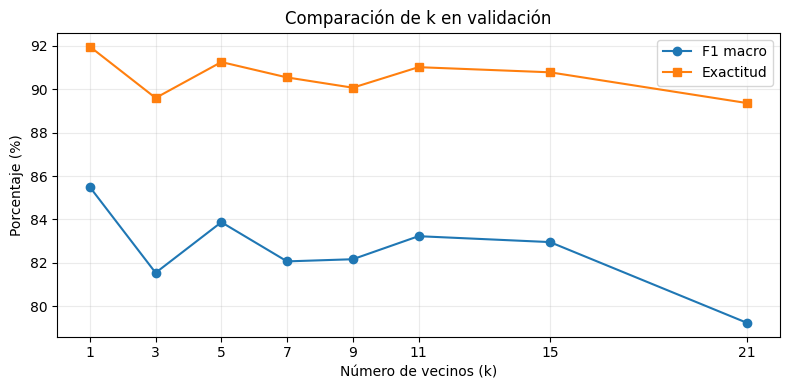

In [5]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
results = []
for k in k_values:
    candidate = KNNClassifier(k=k).fit(X_train_scaled, y_train)
    pred_val = candidate.predict(X_val_scaled)
    cm_val = confusion_matrix(y_val, pred_val, labels=class_labels)
    rec_val = recall_per_class(cm_val)
    prec_val = precision_per_class(cm_val)
    f1_val = f1_per_class(prec_val, rec_val)
    results.append({
        "k": k,
        "Exactitud validación (%)": 100 * accuracy(y_val, pred_val),
        "F1 macro validación (%)": 100 * f1_val.mean(),
        "Recall patológico (%)": 100 * rec_val[list(class_labels).index(3)] if 3 in class_labels else np.nan
    })

comparison = pd.DataFrame(results)
best_row = comparison.sort_values(
    ["F1 macro validación (%)", "k"], ascending=[False, True]
).iloc[0]
best_k = int(best_row["k"])
display(comparison.round(2))
print(f"Mejor k según F1 macro de validación: {best_k}")

plt.figure(figsize=(8, 4))
plt.plot(comparison["k"], comparison["F1 macro validación (%)"], marker="o", label="F1 macro")
plt.plot(comparison["k"], comparison["Exactitud validación (%)"], marker="s", label="Exactitud")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("Porcentaje (%)")
plt.title("Comparación de k en validación")
plt.xticks(k_values)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

#### **Entrenamiento definitivo con el mejor k**

Después de seleccionar **k** con validación, se reúnen los datos de entrenamiento y validación para entrenar el modelo definitivo. La estandarización se recalcula exclusivamente sobre ese conjunto combinado, **sin incorporar prueba**.

In [6]:
mean_dev = X_dev.mean(axis=0)
std_dev = X_dev.std(axis=0)
std_dev[std_dev == 0] = 1.0
X_dev_scaled = (X_dev - mean_dev) / std_dev
X_test_scaled = (X_test - mean_dev) / std_dev

model = KNNClassifier(k=best_k).fit(X_dev_scaled, y_dev)
train_preds = model.predict(X_dev_scaled)
train_accuracy = accuracy(y_dev, train_preds)

print(f"k seleccionado: {best_k}")
print(f"Registros usados para entrenamiento definitivo: {len(y_dev)}")
print(f"Exactitud sobre entrenamiento definitivo: {train_accuracy * 100:.2f}%")

k seleccionado: 1
Registros usados para entrenamiento definitivo: 1691
Exactitud sobre entrenamiento definitivo: 99.88%


#### **Prueba y evaluación final (matriz de confusión, Recall y F1-Score)**

El conjunto de prueba se evalúa **una sola vez** después de seleccionar **k**. La exactitud mide el porcentaje global de aciertos; el **recall** y el **F1 por clase** permiten identificar debilidades en las categorías minoritarias.

In [7]:
test_preds = model.predict(X_test_scaled)
test_accuracy = accuracy(y_test, test_preds)
matrix = confusion_matrix(y_test, test_preds, labels=class_labels)
recalls = recall_per_class(matrix)
precisions = precision_per_class(matrix)
f1s = f1_per_class(precisions, recalls)

metrics = pd.DataFrame({
    "Clase": [class_names.get(int(c), str(c)) for c in class_labels],
    "Precisión (%)": 100 * precisions,
    "Recall (%)": 100 * recalls,
    "F1-score (%)": 100 * f1s,
    "Soporte": matrix.sum(axis=1)
})
print(f"Exactitud final de prueba: {test_accuracy * 100:.2f}%")
print(f"F1 macro final de prueba: {np.mean(f1s) * 100:.2f}%")
display(metrics.round(2))
print("\nMatriz de confusión (filas reales, columnas predichas):")
display(pd.DataFrame(
    matrix,
    index=[f"Real: {class_names.get(int(c), c)}" for c in class_labels],
    columns=[f"Predicho: {class_names.get(int(c), c)}" for c in class_labels]
))

Exactitud final de prueba: 90.07%
F1 macro final de prueba: 82.26%


,Clase,Precisión (%),Recall (%),F1-score (%),Soporte
0,Normal,93.49,95.76,94.61,330
1,Sospechoso,66.67,62.07,64.29,58
2,Patológico,93.55,82.86,87.88,35



Matriz de confusión (filas reales, columnas predichas):


,Predicho: Normal,Predicho: Sospechoso,Predicho: Patológico
Real: Normal,316,13,1
Real: Sospechoso,21,36,1
Real: Patológico,1,5,29


#### **Análisis y conclusiones finales del modelo (KNN)**

**Metodología.** Se utilizó un clasificador KNN implementado desde cero con NumPy. Se retiraron los duplicados exactos antes de dividir los datos para reducir el riesgo de que observaciones idénticas aparecieran en distintos conjuntos. La partición estratificada mantuvo aproximadamente la proporción de las tres clases en entrenamiento, validación y prueba.

**Selección del hiperparámetro.** El valor de **k** se eligió comparando distintos candidatos exclusivamente en validación y maximizando **F1 macro**, una métrica pertinente ante el desequilibrio de clases. La prueba se mantuvo reservada para estimar el desempeño final sin favorecer artificialmente el resultado.

**Interpretación.** Una exactitud alta no garantiza una detección igualmente buena de las clases Sospechosa y Patológica. Por eso, los resultados deben interpretarse junto con la matriz de confusión, el recall y el F1-score por clase. La diferencia entre exactitud de entrenamiento y prueba también ayuda a identificar posibles problemas de generalización.

**Limitaciones.** Los resultados dependen de la partición aleatoria elegida y de la distancia euclidiana con votación mayoritaria. La comparación realizada no incluye ponderación por distancia, validación cruzada ni técnicas específicas de tratamiento del desbalance.

**Nota:** Este análisis es académico y no debe utilizarse para emitir diagnósticos clínicos.